In [ ]:
# ============================================
# REAL ESTATE VALUATION - EXPLORATORY DATA ANALYSIS
# Dataset: 414 Rows
# Libraries: NumPy, Pandas, Matplotlib
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. LOAD DATASET
# Use the already loaded dataset in your kernel
df = data.copy()

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

Column names

In [48]:

price = "Y house price of unit area"
age = "X2 house age"
mrt = "X3 distance to the nearest MRT station"
stores = "X4 number of convenience stores"


2. Display Datasheet Information

In [ ]:


print("\n========== FIRST 5 ROWS ==========")
print(df.head())

print("\n========== LAST 5 ROWS ==========")
print(df.tail())

print("\n========== DATASET SHAPE ==========")
print(df.shape)

print("\n========== DATASET INFORMATION ==========")
df.info()

print("\n========== STATISTICAL SUMMARY ==========")
print(df.describe())



========== FIRST 5 ROWS ==========
   No  X1 transaction date  X2 house age  \
0   1          2012.916667          32.0   
1   2          2012.916667          19.5   
2   3          2013.583333          13.3   
3   4          2013.500000          13.3   
4   5          2012.833333           5.0   

   X3 distance to the nearest MRT station  X4 number of convenience stores  \
0                                84.87882                               10   
1                               306.59470                                9   
2                               561.98450                                5   
3                               561.98450                                5   
4                               390.56840                                5   

   X5 latitude  X6 longitude  Y house price of unit area  
0     24.98298     121.54024                        37.9  
1     24.98034     121.53951                        42.2  
2     24.98746     121.54391                        4

**QUESTION-1**

**What are thev average,median,minimum and maximum house prices per unit area?**

3. HOUSE PRICE STATISTICS USING NUMPY


In [ ]:

prices = df[price].dropna().to_numpy()

print("\n========== HOUSE PRICE ANALYSIS ==========")

print("Average Price:", np.mean(prices))
print("Median Price:", np.median(prices))
print("Minimum Price:", np.min(prices))
print("Maximum Price:", np.max(prices))



========== HOUSE PRICE ANALYSIS ==========
Average Price: 37.980193236714975
Median Price: 38.45
Minimum Price: 7.6
Maximum Price: 117.5


**QUESTION-2**

**What is the average house age??**

 4.  AVERAGE HOUSE AGE


In [44]:

print("\n========== HOUSE AGE ANALYSIS ==========")

print("Average House Age:", df[age].mean(), "years")




========== HOUSE AGE ANALYSIS ==========
Average House Age: 17.71256038647343 years


**Question-3**

**Compare average price for propertis near and far from MRT station using a simple threshold chosen by your team.**

5. MRT DISTANCE ANALYSIS


In [45]:

# Selected threshold = 1000 metres

threshold = 1000
df["MRT Category"] = np.where(
    df[mrt] <= threshold,
    "Near MRT",
    "Far from MRT"
)
print("\n========== NEAR VS FAR MRT ==========")

near_properties = df[df[mrt] <= threshold]
far_properties = df[df[mrt] > threshold]

print("Near MRT Average Price:",
      near_properties[price].mean())

print("Far MRT Average Price:",
      far_properties[price].mean())

print("\nMRT Group Analysis:")
print(df.groupby("MRT Category")[price].agg(
    ["count", "mean", "median"]
))



========== NEAR VS FAR MRT ==========
Near MRT Average Price: 44.65471014492754
Far MRT Average Price: 24.63115942028986

MRT Group Analysis:
              count       mean  median
MRT Category                          
Far from MRT    138  24.631159   24.15
Near MRT        276  44.654710   42.65


**Question-4**

**Do records with more nearby convinience stores show a different average price?**

6. CONVENIENCE STORE ANALYSIS


In [ ]:

print("\n========== CONVENIENCE STORE COUNTS ==========")

print(df[stores].value_counts().sort_index())

print("\n========== AVERAGE PRICE BY STORES ==========")

store_analysis = df.groupby(stores)[price].agg(
    ["count", "mean", "median"]
)
print(store_analysis)




========== CONVENIENCE STORE COUNTS ==========
X4 number of convenience stores
0     67
1     46
2     24
3     46
4     31
5     67
6     37
7     31
8     30
9     25
10    10
Name: count, dtype: int64

========== AVERAGE PRICE BY STORES ==========
                                 count       mean  median
X4 number of convenience stores                          
0                                   67  26.462687   22.30
1                                   46  31.839130   28.70
2                                   24  31.412500   30.65
3                                   46  29.536957   28.25
4                                   31  37.474194   37.40
5                                   67  44.729851   44.50
6                                   37  46.951351   45.70
7                                   31  43.848387   42.00
8                                   30  44.696667   42.75
9                                   25  51.732000   50.80
10                                  10  48.430000   

**Question-5**

**Find th 10 highest-priced records.**

7. TOP 10 HIGHEST-PRICED RECORDS


In [ ]:

print("\n========== TOP 10 HIGHEST-PRICED PROPERTIES ==========")

top_10 = df.sort_values(
    by=price,
    ascending=False
).head(10)

print(top_10.to_string(index=False))


========== TOP 10 HIGHEST-PRICED PROPERTIES ==========
 No  X1 transaction date  X2 house age  X3 distance to the nearest MRT station  X4 number of convenience stores  X5 latitude  X6 longitude  Y house price of unit area MRT Category
271          2013.333333          10.8                               252.58220                                1     24.97460     121.53046                       117.5     Near MRT
221          2013.333333          37.2                               186.51010                                9     24.97703     121.54265                        78.3     Near MRT
313          2013.583333          35.4                               318.52920                                9     24.97071     121.54069                        78.0     Near MRT
167          2013.416667           0.0                               292.99780                                6     24.97744     121.54458                        73.6     Near MRT
106          2012.833333           0.0      

**Question-6**

**Check for missing values and duplicates?**

In [47]:

print("\n========== MISSING VALUES ==========")
print(df.isnull().sum())

print("Total Missing Values:", df.isnull().sum().sum())
# 9. CHECK DUPLICATE RECORDS

print("\n========== DUPLICATE RECORDS ==========")
print("Duplicate Rows:", df.duplicated().sum())




========== MISSING VALUES ==========
No                                        0
X1 transaction date                       0
X2 house age                              0
X3 distance to the nearest MRT station    0
X4 number of convenience stores           0
X5 latitude                               0
X6 longitude                              0
Y house price of unit area                0
MRT Category                              0
dtype: int64
Total Missing Values: 0

========== DUPLICATE RECORDS ==========
Duplicate Rows: 0


# 10. HISTOGRAM OF HOUSE PRICES


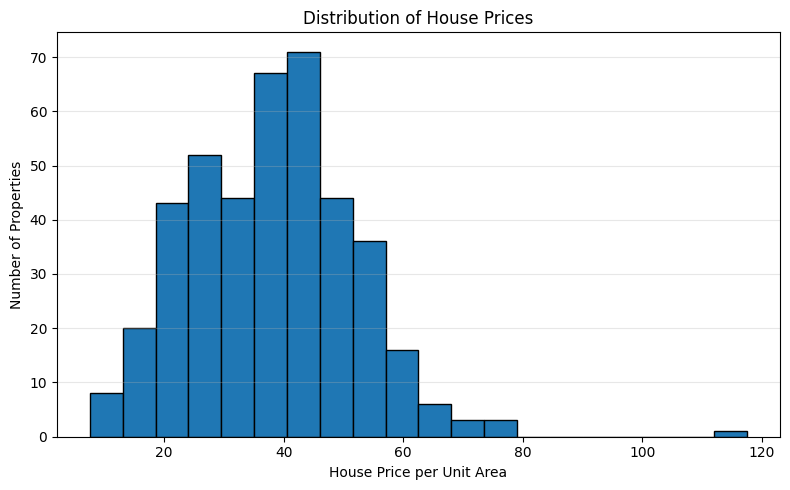

In [ ]:

plt.figure(figsize=(8, 5))

plt.hist(prices, bins=20, edgecolor="black")

plt.title("Distribution of House Prices")
plt.xlabel("House Price per Unit Area")
plt.ylabel("Number of Properties")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("house_price_histogram.png")
plt.show()


 11. SCATTER PLOT: MRT DISTANCE VS PRICE


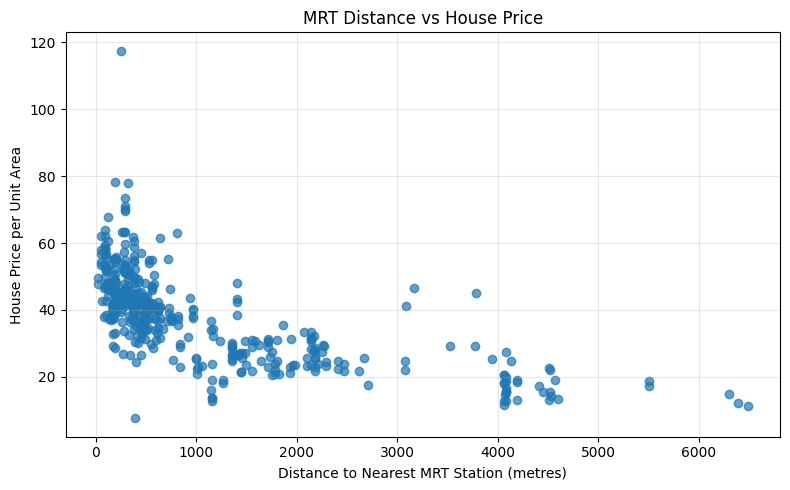

In [ ]:

plt.figure(figsize=(8, 5))

plt.scatter(
    df[mrt],
    df[price],
    alpha=0.7
)

plt.title("MRT Distance vs House Price")
plt.xlabel("Distance to Nearest MRT Station (metres)")
plt.ylabel("House Price per Unit Area")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("mrt_distance_vs_price.png")
plt.show()


12. THREE OBSERVATIONS


In [ ]:

print("\n========== THREE OBSERVATIONS ==========")

near_avg = near_properties[price].mean()
far_avg = far_properties[price].mean()

if near_avg > far_avg:
    print("1. Properties within 1000 metres of an MRT station "
          "have a higher average price than properties farther away.")
elif near_avg < far_avg:
    print("1. Properties farther than 1000 metres from an MRT station "
          "have a higher average price than nearby properties.")
else:
    print("1. Both MRT distance groups have the same average price.")

store_means = store_analysis["mean"]

print("2. The average price differs across convenience-store "
      "count groups. The highest average is for properties "
      "with", store_means.idxmax(),
      "nearby convenience stores.")

print("3. The price distribution has a mean of",
      round(np.mean(prices), 2),
      "and a median of",
      round(np.median(prices), 2),
      ". Compare these values and the histogram to understand "
      "the distribution of house prices.")

print("\n========== EDA COMPLETED SUCCESSFULLY ==========")



========== THREE OBSERVATIONS ==========
1. Properties within 1000 metres of an MRT station have a higher average price than properties farther away.
2. The average price differs across convenience-store count groups. The highest average is for properties with 9 nearby convenience stores.
3. The price distribution has a mean of 37.98 and a median of 38.45 . Compare these values and the histogram to understand the distribution of house prices.

========== EDA COMPLETED SUCCESSFULLY ==========
